# RetroPath 2.0: workflow e utilizzo

## Introduzione
Per riuscire a sviluppare un tool che possa predire pathway metabolici non annotati e/o sufficientemente curati sui database pubblici (KEGG, MetaCyc, MetaNetX...), ci serviamo di RetroPath 2.0, un algoritmo di retrosintesi atto a trovare possibili reazioni (e relativi enzimi) che colleghino i composti target (source compounds) ai metaboliti principali (sink compounds) presenti nel metabolismo del batterio che va ingegnerizzato.

Per fare ciò, una serie di reaction rules sono applicate iterativamente sui composti fino a raggiungere una condizione di stop (tipicamente il raggiungimento dei sink o il numero di iterazioni). Le reaction rules in generale non sono altro che una descrizione delle modifiche strutturali che avvengono in una molecola quando si passa da reagenti a prodotti. Nel caso della retrosintesi le regole sono invertite, così da calcolare i reagenti a partire dai prodotti.

Integrando questo workflow con i nostri scopi di biorisanamento, confidiamo di essere in grado di sviluppare un tool che possa predire i pathway di degradazione degli inquinanti meno conosciuti/annotati, considerando proprio questi ultimi come i source compounds e i composti del metabolismo centrale come i sink compounds.

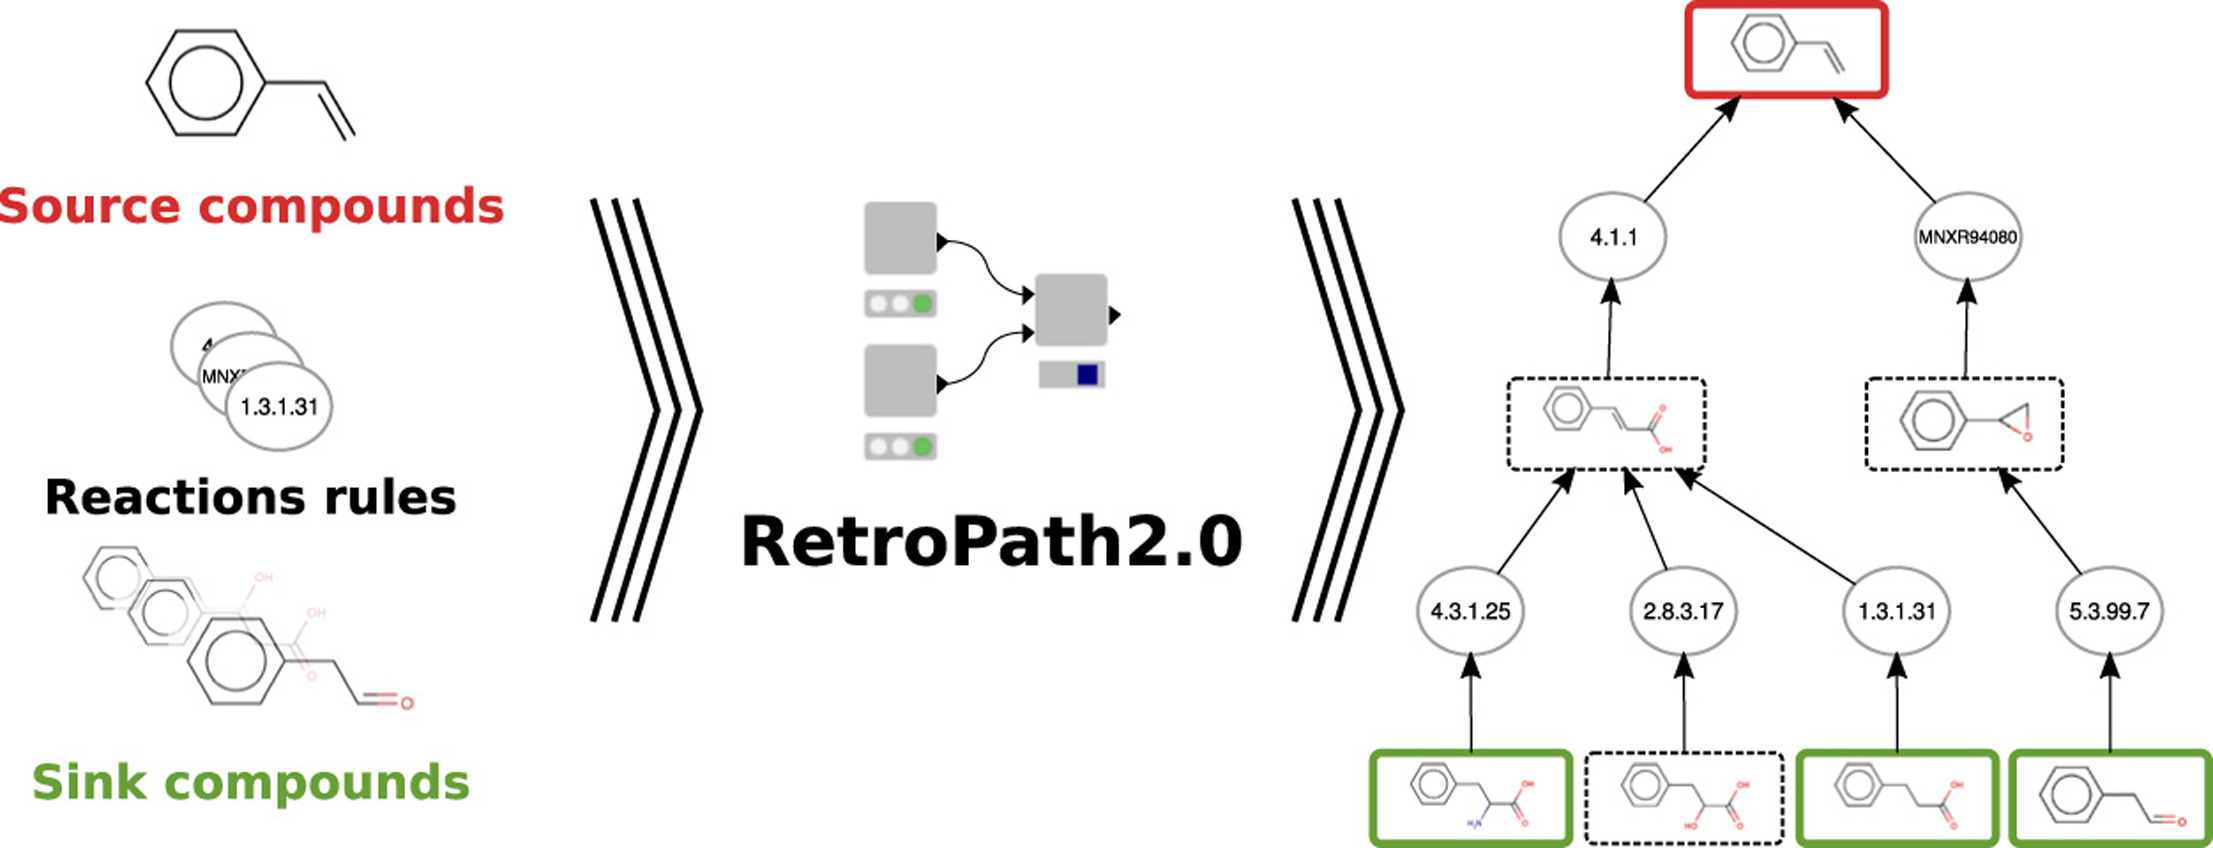

## Input e output
Come anticipato, il tool richiede in input tre elementi: il composto target (ciò che si vuole degradare, *source compound*), i metaboliti centrali (ciò a cui si vuole arrivare, *sink compounds*) e le *reactions rules*. Queste ultime possono essere ottenute con una query al database di **RetroRules**, filtrando per il nome del substrato o la sua struttura molecolare (rappresentata dall'*International Chemical Identifier* - InChI). 

Il formato di tutti e tre è .csv: sia *source* che *sink* seguono la struttura 'Name', 'InChI'; le *rules* hanno invece un numero maggiore di colonne, ma quelle più informative sono quelle dell'**EC number**, del **diameter**, e dello **score**. Il primo parametro riguarda la categoria a cui appartiene l'enzima in grando di compiere quella determinata trasformazione chimica; il secondo misura la specificità della reazione (maggiore diametro = reazione più specifica); il terzo è invece un valore associato alla disponibilità della sequenza enzimatica.

Per quanto concerne l'output, si tratta sempre di un file .csv, facilmente visualizzabile aprendolo ad esempio con Excel, composto da 14 colonne:
- **Initial source**: composto di partenza che si intende degradare
- **Transformation ID**: specifico per ogni riga, è una numerazione ordinata degli step
- **Reaction SMILES**: rappresentazione della reazione secondo il metodo *Simplified Molecular Input Line Entry System*
- **Substrate SMILES**: rappresentazione del reagente secondo il metodo *Simplified Molecular Input Line Entry System*
- **Substrate InChI**: rappresentazione del reagente secondo l'identificatore InChI
- **Product SMILES**: rappresentazione del prodotto secondo il metodo *Simplified Molecular Input Line Entry System*
- **Product InChI**: rappresentazione del prodotto secondo l'identificatore InChI
- **In Sink**: 1 se il prodotto ottenuto da questa trasformazione fa parte dei *sink compounds*, altrimenti 0
- **Sink name**: se la colonna precedente ha valore 1, contiene il nome del *sink compound*, altrimenti None 
- **Diameter**: diametro, e quindi specificità, della *reaction rule* applicata
- **Rule ID**: ID della *reaction rule* applicata
- **EC number**: Enzyme Code(s) associato/i alla *reaction rule* applicata 
- **Score**: *score* della *reaction rule* applicata, basato sulla disponibilità della sequenza enzimatica
- **Iteration**: numero di trasformazioni applicate fino a quel punto a partire dall'*Initial source*, l'indicizzazione parte da 0

## Esempio
Proponiamo un piccolo esempio di degradazione della parte monomerica del PET, ovvero il MET (monoetilene tereftalato), che sarà proprio il nostro *source compound*. Per quanto riguarda i *sink compounds* ...
Su KEGG, è possibile recuperare il percorso: 

MET --> tereftalato --> tereftalato-1,2-diidrodiolo --> acido 3,4-diidrossibenzoico --> cis,cis-beta-muconato --> muconolattone

Vediamo ora cosa propone RetroPath2.0, automatizzando il processo.

## Prossimi passi
Attualmente stiamo esplorando ulteriormente quanto offerto dalla suite di RetroPath, la quale comprende anche strumenti come **rp2paths** (utile all'estrazione dei percorsi a partire dall'output di RP2.0 e alla loro visualizzazione grafica) e **rptools** (insieme di strumenti che permettono di eseguire analisi ulteriori su percorsi precedentemente predetti, come ad esempio l'aggiunta dei cofattori appropriati, analisi flussomiche e ranking dei percorsi).

Oltre alla parte di predizione dei percorsi, ci stiamo anche concentrando sulla parte che cronologicamente nella pipeline del tool, ovvero il riperimento di percorsi già esistenti. Per fare ciò, intendiamo servirci di alcuni parser per gestire le informazioni relative ai pathway già annotati sui vari database che vogliamo consultare (per ora KEGG e MetaCyc).

Vogliamo poi far convergere i due casi (riperimento percorsi conosciuti e predizione sconosciuti) in una serie di azioni che sia univoca; idealmente quest'ultima sarà: visualizzazione del/dei percorso/i proposto/i, reperimento degli enzimi necessari a compiere le reazioni richieste che Rhodococcus Opacus PD630 non possiede, acquisizione delle relative sequenze nucleotidiche attraverso ricerca in specie omologhe, assemblaggio del plasmide e quindi output finale.